# Handwriting AI: Writer Identification with a CNN

**Destiny Jerez**

A convolutional neural network that identifies which of 4 people wrote a handwriting sample. It was trained on 100 scanned samples (25 per writer) and reached **80% accuracy on the held-out test set (8 of 10 images)**.

## 1. Setup

In [15]:
!pip install tensorflow matplotlib numpy scikit-learn seaborn Pillow -q

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import zipfile

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.19.0


## 2. Upload the dataset

The dataset zip has one folder per writer (25 handwriting images each). It isn't included in this repo because it contains personal handwriting samples.

In [16]:
from google.colab import files
print('Please upload your datasets.zip file...')
uploaded = files.upload()

zip_filename = list(uploaded.keys())[0]
with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall('/content/datasets')

print('\nDataset extracted. Folder structure:')
for root, dirs, files_list in os.walk('/content/datasets'):
    level = root.replace('/content/datasets', '').count(os.sep)
    indent = ' ' * 2 * level
    print(f'{indent}{os.path.basename(root)}/')
    if level == 1:
        print(f'{indent}  → {len(files_list)} images found')



Please upload your datasets.zip file...


Saving Dataset (2).zip to Dataset (2) (1).zip

Dataset extracted. Folder structure:
datasets/
  Dataset/
    → 0 images found
    Meliza/
    Destiny/
    Leila/
    Karolina/


## 3. Load and preprocess

Each image is converted to grayscale, resized to 128 × 128 and scaled to [0, 1].

In [17]:
IMG_SIZE = 128 #all images will be resized to 128 × 128 pixels
DATASET_PATH = '/content/datasets'

#labeling each sample starting from 0
LABEL_MAP = {
    'karolina': 0,
    'leila':    1,
    'destiny':  2,
    'meliza':   3,
}
CLASS_NAMES = ['Karolina', 'Leila', 'Destiny', 'Meliza']
NUM_CLASSES = len(CLASS_NAMES)

#preprocessing the image
def preprocess_image(img_path):
    """Load → grayscale → resize → normalise → return float32 array."""
    img = Image.open(img_path).convert('L') #step 1:Grayscale the image
    img = img.resize((IMG_SIZE, IMG_SIZE)) #step 2: Resize the image
    img_array = np.array(img, dtype=np.float32) / 255.0 #step 3: Normalise [0,1]
    return img_array

def load_dataset(dataset_path, label_map):
    """Walk dataset_path, load every image, return (X, y) arrays."""
    images, labels = [], []

    for person_name, label in label_map.items():
        person_folder = None
        for root, dirs, _ in os.walk(dataset_path):
            for d in dirs:
                if d.lower() == person_name.lower():
                    person_folder = os.path.join(root, d)
                    break
            if person_folder:
                break

        if person_folder is None:
            print(f'  Folder not found for: {person_name}')
            continue

        count = 0
        for fname in os.listdir(person_folder):
            if fname.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')):
                img_path = os.path.join(person_folder, fname)
                try:
                    images.append(preprocess_image(img_path))
                    labels.append(label)
                    count += 1
                except Exception as e:
                    print(f'   Skipped {fname}: {e}')

        print(f'  {person_name.capitalize()}: {count} images loaded (label={label})')

    return np.array(images), np.array(labels)

print('Loading and preprocessing images...')
X, y = load_dataset(DATASET_PATH, LABEL_MAP)
X = X.reshape(-1, IMG_SIZE, IMG_SIZE, 1)

#reshape for CNN
X = X.reshape(-1, IMG_SIZE, IMG_SIZE, 1)
print(f'\nDataset Summary:')
print(f'  Total images : {len(X)}')
print(f'  Image shape  : {X[0].shape}')
for i, name in enumerate(CLASS_NAMES):
    print(f'  {name:<10}: {np.sum(y == i)} images')

Loading and preprocessing images...
  Karolina: 25 images loaded (label=0)
  Leila: 25 images loaded (label=1)
  Destiny: 25 images loaded (label=2)
  Meliza: 25 images loaded (label=3)

Dataset Summary:
  Total images : 100
  Image shape  : (128, 128, 1)
  Karolina  : 25 images
  Leila     : 25 images
  Destiny   : 25 images
  Meliza    : 25 images


## 4. Sample images

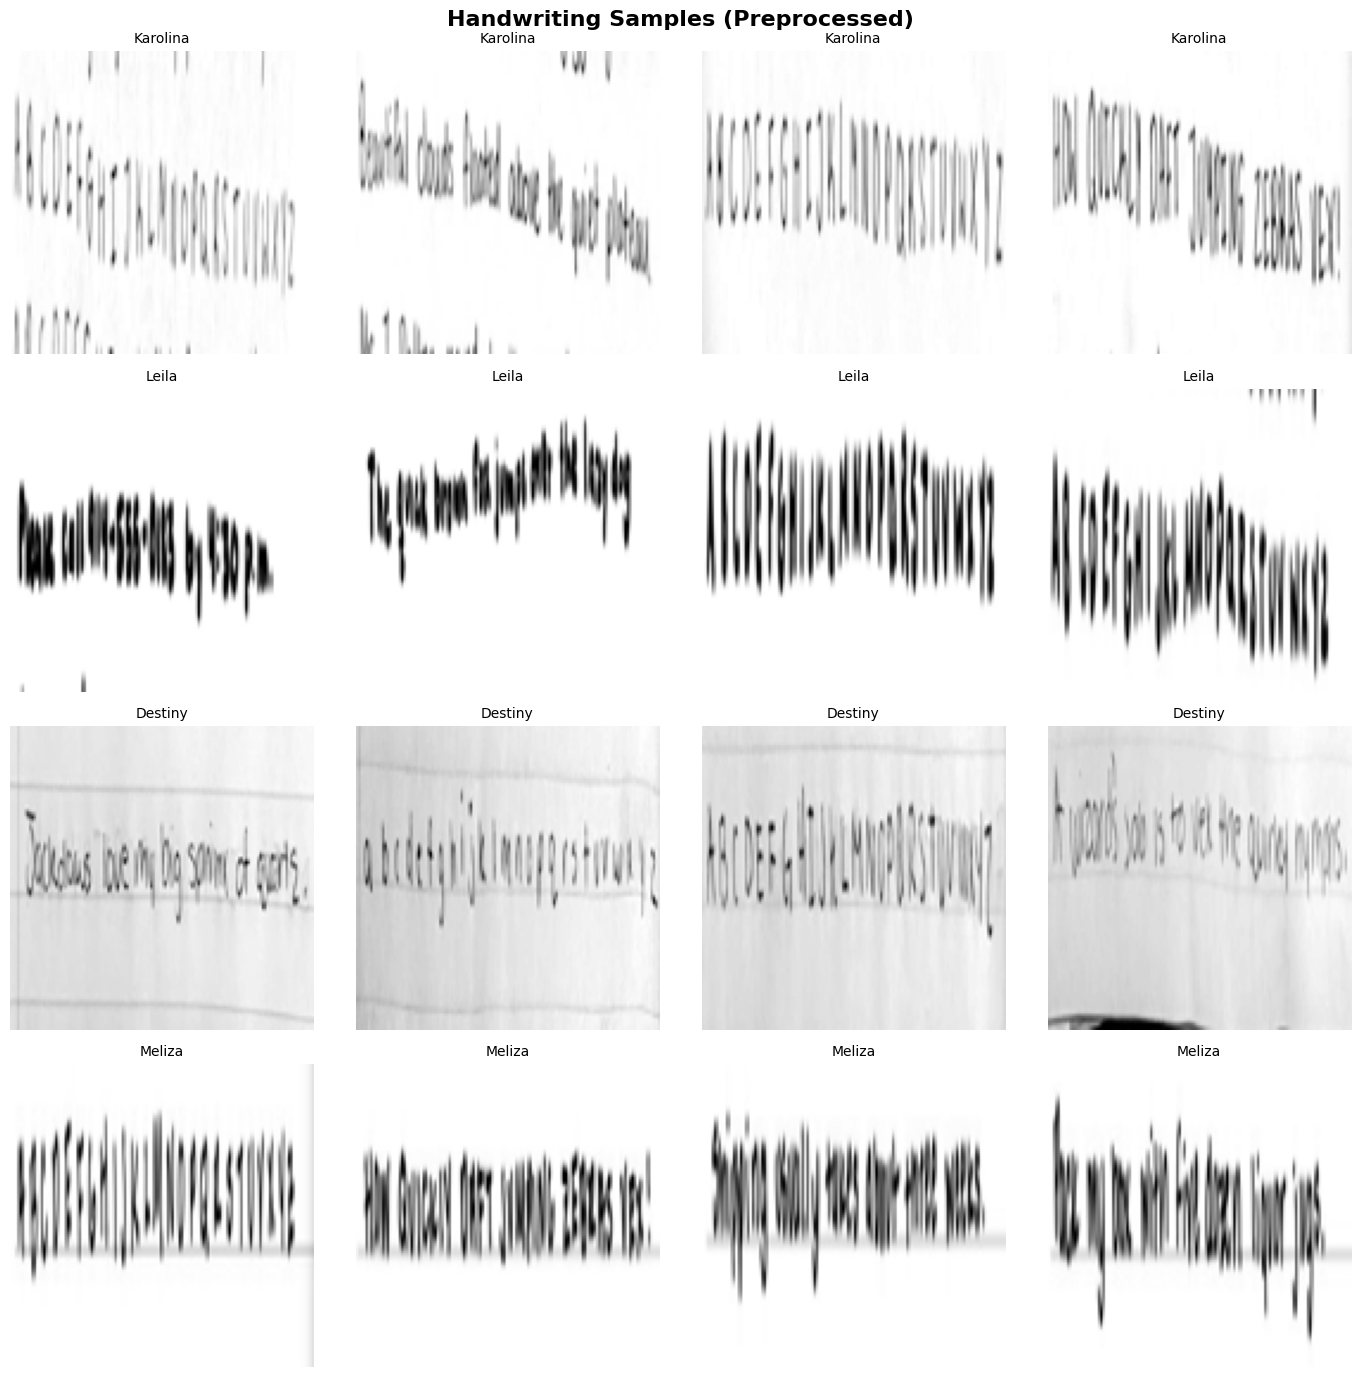

In [18]:
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(14, 14))
fig.suptitle('Handwriting Samples (Preprocessed)', fontsize=16, fontweight='bold')
for person_idx, person_name in enumerate(CLASS_NAMES):
    person_indices = np.where(y == person_idx)[0]
    sample_indices = person_indices[:4]

    for col, img_idx in enumerate(sample_indices):
        ax = axes[person_idx][col]
        ax.imshow(X[img_idx].reshape(IMG_SIZE, IMG_SIZE), cmap='gray')
        ax.set_title(person_name, fontsize=10)
        ax.axis('off')

plt.tight_layout()
plt.savefig('sample_images.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Class balancing

Augmentation fills in any writer with fewer samples. Every writer already had 25 images, so no augmentation was needed in this run.

In [19]:
#augmentation settings
augmentor = ImageDataGenerator(
    rotation_range=8,              #rotation
    width_shift_range=0.08,        #horizontal shift
    height_shift_range=0.08,       #vertical shift
    shear_range=0.05,              #slight shear
    zoom_range=0.08,               #slight zoom in/out
    brightness_range=[0.85, 1.15], #lighting variation
    fill_mode='nearest'
)

def augment_class(X, y, target_label, target_count):
    """Augment one class until it reaches target_count samples."""
    class_indices = np.where(y == target_label)[0]
    class_images  = X[class_indices]
    current_count = len(class_images)
    needed = target_count - current_count

    if needed <= 0:
        return X, y

    new_images, new_labels = [], []
    gen = augmentor.flow(class_images, batch_size=1)
    for _ in range(needed):
        aug_img = np.clip(next(gen)[0], 0, 1)
        new_images.append(aug_img)
        new_labels.append(target_label)
    X_aug = np.concatenate([X, np.array(new_images)], axis=0)
    y_aug = np.concatenate([y, np.array(new_labels)], axis=0)
    print(f'  {CLASS_NAMES[target_label]}: {current_count} → {current_count + needed} images')
    return X_aug, y_aug

TARGET_COUNT = max(np.bincount(y))
print(f'Target samples per class: {TARGET_COUNT}')

X_bal, y_bal = X.copy(), y.copy()
for label_idx in range(NUM_CLASSES):
    count = np.sum(y_bal == label_idx)
    if count < TARGET_COUNT:
        X_bal, y_bal = augment_class(X_bal, y_bal, label_idx, TARGET_COUNT)
    else:
        print(f'  {CLASS_NAMES[label_idx]}: already has {count} images, no augmentation will be needed')

print(f'\nBalanced Dataset:')
for i, name in enumerate(CLASS_NAMES):
    print(f'  {name:<10}: {np.sum(y_bal == i)} images')
print(f'  Total   : {len(X_bal)} images')

Target samples per class: 25
  Karolina: already has 25 images, no augmentation will be needed
  Leila: already has 25 images, no augmentation will be needed
  Destiny: already has 25 images, no augmentation will be needed
  Meliza: already has 25 images, no augmentation will be needed

Balanced Dataset:
  Karolina  : 25 images
  Leila     : 25 images
  Destiny   : 25 images
  Meliza    : 25 images
  Total   : 100 images


## 6. Train / validation / test split (80 / 10 / 10)

In [20]:
#shuffle before splitting:
indices     = np.random.permutation(len(X_bal))
X_shuffled  = X_bal[indices]
y_shuffled  = y_bal[indices]

#80 % train, 20 % temp:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_shuffled, y_shuffled,
    test_size=0.2,
    random_state=42,
    stratify=y_shuffled
)

#50/50 split of temp,10 % val, 10 % test:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)
print('Dataset Split:')
print(f'  Training: {len(X_train)} images (80 %)')
print(f'  Validation: {len(X_val)} images (10 %)')
print(f'  Testing: {len(X_test)} images (10 %)')

y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes=NUM_CLASSES)
y_val_cat   = tf.keras.utils.to_categorical(y_val,   num_classes=NUM_CLASSES)
y_test_cat  = tf.keras.utils.to_categorical(y_test,  num_classes=NUM_CLASSES)

Dataset Split:
  Training: 80 images (80 %)
  Validation: 10 images (10 %)
  Testing: 10 images (10 %)


## 7. CNN model

In [21]:
def build_cnn_model(input_shape=(IMG_SIZE, IMG_SIZE, 1), num_classes=NUM_CLASSES):
    model = keras.Sequential([
        layers.Conv2D(16, (3, 3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D(2, 2),

        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D(2, 2),

        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_cnn_model()

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 126, 126, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     1,843,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,848,324 (7.05 MB)

 Trainable params: 1,848,324 (7.05 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Training

Early stopping (patience 10), learning-rate reduction on plateau, and checkpointing of the best validation accuracy.

In [22]:
callbacks = [
    #would stop early if validation loss stops improving
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        'best_handwriting_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
]

print('Training starting')
history = model.fit(
    X_train, y_train_cat,
    epochs=50,
    batch_size=8,
    validation_data=(X_val, y_val_cat),
    callbacks=callbacks,
    verbose=1
)
print('\nTraining completed')

Training starting
Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.2768 - loss: 3.3545
Epoch 1: val_accuracy improved from None to 0.20000, saving model to best_handwriting_model.keras

Epoch 1: finished saving model to best_handwriting_model.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 462ms/step - accuracy: 0.2375 - loss: 2.7102 - val_accuracy: 0.2000 - val_loss: 1.3512 - learning_rate: 0.0010
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - accuracy: 0.2987 - loss: 1.3287
Epoch 2: val_accuracy improved from 0.20000 to 0.40000, saving model to best_handwriting_model.keras

Epoch 2: finished saving model to best_handwriting_model.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 312ms/step - accuracy: 0.3500 - loss: 1.3049 - val_accuracy: 0.4000 - val_loss: 1.2407 - learning_rate: 0.0010
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.3760 - loss: 1.2196
Epoch 3: val_accuracy improved from 0.40000 to 0.50000, saving model to best_handwriting_model.keras

Epoch 3: fini

## 9. Training curves

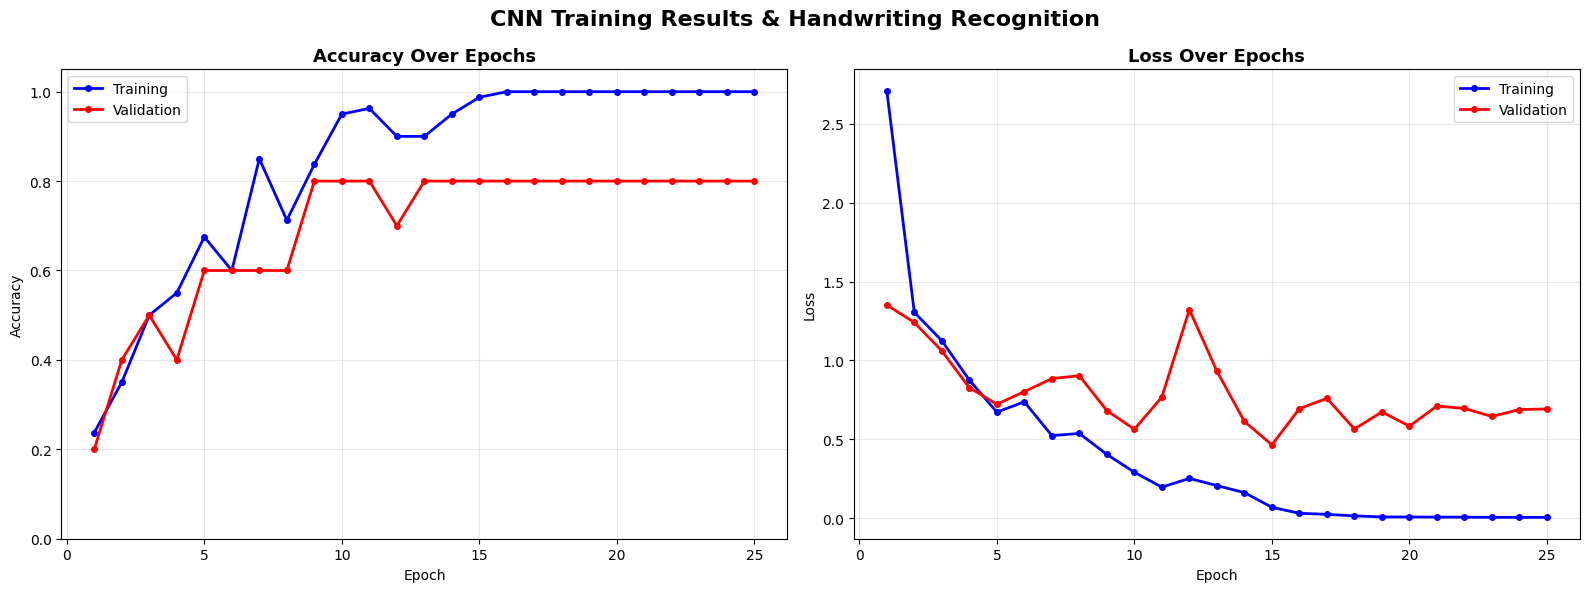

Training curves saved to training_curves.png


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('CNN Training Results & Handwriting Recognition', fontsize=16, fontweight='bold')

epochs_ran = range(1, len(history.history['accuracy']) + 1)

#accuracy
axes[0].plot(epochs_ran, history.history['accuracy'],     'b-o', markersize=4, linewidth=2, label='Training')
axes[0].plot(epochs_ran, history.history['val_accuracy'], 'r-o', markersize=4, linewidth=2, label='Validation')
axes[0].set_title('Accuracy Over Epochs', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0, 1.05])
#the loss
axes[1].plot(epochs_ran, history.history['loss'],     'b-o', markersize=4, linewidth=2, label='Training')
axes[1].plot(epochs_ran, history.history['val_loss'], 'r-o', markersize=4, linewidth=2, label='Validation')
axes[1].set_title('Loss Over Epochs', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Training curves saved to training_curves.png')

## 10. Test results

In [24]:
best_model = keras.models.load_model('best_handwriting_model.keras')

test_loss, test_accuracy = best_model.evaluate(X_test, y_test_cat, verbose=0)
print(f'Test Accuracy : {test_accuracy * 100:.2f} %')
print(f'Test Loss     : {test_loss:.4f}')
y_pred_probs = best_model.predict(X_test)
y_pred       = np.argmax(y_pred_probs, axis=1)

print('\nClassification:')
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES))

Test Accuracy : 80.00 %
Test Loss     : 0.3940
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step

Classification:
              precision    recall  f1-score   support

    Karolina       0.60      1.00      0.75         3
       Leila       1.00      1.00      1.00         2
     Destiny       1.00      0.33      0.50         3
      Meliza       1.00      1.00      1.00         2

    accuracy                           0.80        10
   macro avg       0.90      0.83      0.81        10
weighted avg       0.88      0.80      0.78        10



## 11. Confusion matrix

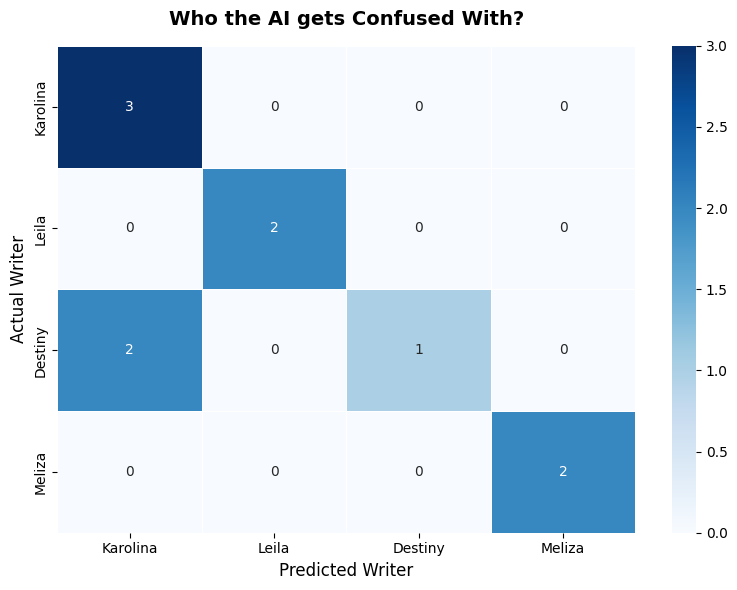

In [25]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    linewidths=0.5
)
plt.title( 'Who the AI gets Confused With?', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Actual Writer',    fontsize=12)
plt.xlabel('Predicted Writer', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


## 12. Try it: identify the writer of a new sample

Upload a handwriting image to identify whose writing it is...


Saving Screenshot 2026-04-22 122705.png to Screenshot 2026-04-22 122705.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


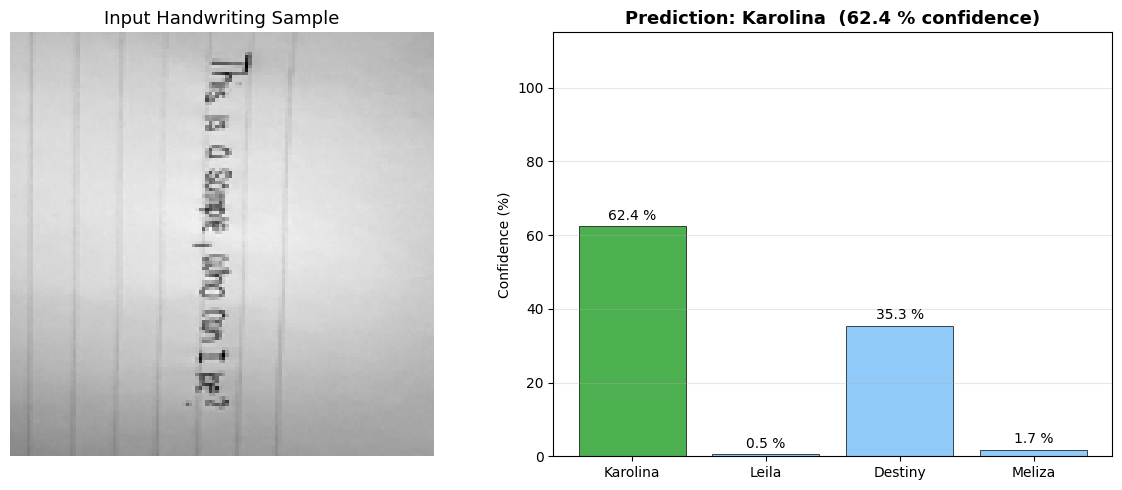


This handwriting belongs to: KAROLINA
Confidence: 62.4 %


In [30]:
from google.colab import files as colab_files

print('Upload a handwriting image to identify whose writing it is...')
uploaded_sample = colab_files.upload()

sample_path  = list(uploaded_sample.keys())[0]
sample_img   = preprocess_image(sample_path)
sample_input = sample_img.reshape(1, IMG_SIZE, IMG_SIZE, 1)

# Predict
prediction_probs = best_model.predict(sample_input)[0]
predicted_class  = np.argmax(prediction_probs)
confidence       = prediction_probs[predicted_class] * 100

# Display
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(sample_img, cmap='gray')
axes[0].set_title('Input Handwriting Sample', fontsize=13)
axes[0].axis('off')

colors = ['#4CAF50' if i == predicted_class else '#90CAF9' for i in range(NUM_CLASSES)]
bars   = axes[1].bar(CLASS_NAMES, prediction_probs * 100, color=colors, edgecolor='black', linewidth=0.5)
axes[1].set_title(
    f'Prediction: {CLASS_NAMES[predicted_class]}  ({confidence:.1f} % confidence)',
    fontsize=13, fontweight='bold'
)
axes[1].set_ylabel('Confidence (%)')
axes[1].set_ylim([0, 115])
axes[1].grid(True, axis='y', alpha=0.3)

for bar, prob in zip(bars, prediction_probs):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{prob * 100:.1f} %',
        ha='center', va='bottom', fontsize=10
    )

plt.tight_layout()
plt.savefig('prediction_result.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\nThis handwriting belongs to: {CLASS_NAMES[predicted_class].upper()}')
print(f'Confidence: {confidence:.1f} %')

## Takeaways

- 80% test accuracy (8 of 10 images). Leila and Meliza were identified perfectly; 2 of Destiny's 3 test samples were mistaken for Karolina's.
- Training accuracy reached 100% while validation stayed at 80%: with only 100 images, the model overfits.
- Next steps: k-fold cross-validation for a more reliable score, augmentation on the training set, more samples per writer, and transfer learning from a pretrained CNN.